# Avance 4: modelos alternativos para estimar la emisión de NOₓ

## 1. Objetivo

Comparar modelos con algoritmos distintos que estiman la misma cantidad, la emisión de NOₓ de la Ciudad de México por zona y tipo de día, con los mismos datos (noviembre–diciembre de 2023, tardes), el mismo esquema de validación (una estación oculta a la vez) y las mismas pruebas de cordura (placebo del domingo). Con la tabla se eligen los dos mejores, se ajustan con una búsqueda de hiperparámetros y se argumenta cuál es el modelo final.

Reglas del ejercicio:

- Todos los modelos estiman emisión; IDW y kriging aparecen solo como piso de concentración.
- Ningún modelo ve febrero–mayo de 2024: es el periodo de prueba del avance 5. `nox-ml tune` rechaza configuraciones que lo incluyan.
- Todo el código de este cuaderno llama a `nox_ml`; los números salen solo de `results/runs/` (la copia versionada de las corridas de `runs/`: `nox-ml run`, `nox-ml compare`, `nox-ml tune`) leídas con `nox_ml.validation.compare` y `report`.

## 2. Los modelos y las referencias

| # | Modelo (`nox_ml`) | Algoritmo | Por qué está en la comparación | Emisión que estima |
|---|---|---|---|---|
| E1 | `inversion_plume` | Inversión bayesiana lineal con pluma gaussiana estacionaria (**baseline**) | Punto de partida: física simple e interpretable, con incertidumbre. Fija lo que los demás deben mejorar | Absoluta, por zona y tipo de día |
| E2 | `inversion_puff` | Inversión bayesiana lineal con puffs y vida química por OH | Quita la hipótesis de estado estacionario: el aire conserva emisiones de horas anteriores | Absoluta |
| E3 | `regularized_ls` | Mínimos cuadrados regularizados y no negativos (ridge/NNLS) sobre la tabla física | Misma física, sin supuesto bayesiano: aísla el efecto del prior | Absoluta |
| E4 | `lognormal_map` | Inversión no lineal con emisiones log-normales (siempre positivas): máximo a posteriori con L-BFGS-B e incertidumbre por aproximación de Laplace | Garantiza emisiones positivas sin truncar y prueba un prior que no es gaussiano | Absoluta |
| E5a | `pinn_plume` | Red neuronal informada por la física (PINN) que aprende el núcleo de advección–difusión + inversión bayesiana | Cambia el transporte analítico por uno aprendido, sin cambiar la inversión | Absoluta |
| E5b | `pinn_puff` | PINN aplicada a cada tramo de puff + inversión bayesiana | Combina el núcleo aprendido con la memoria de los puffs | Absoluta |
| E5c | `pinn_joint` | PINN entrenada con la física y las estaciones a la vez | **Queda fuera del avance 4** (sección 2.3): en la investigación no mejoró el ajuste y cuesta 12–17 veces más tiempo | Absoluta |
| E6 | `rf_deweather` | Normalización meteorológica con bosque aleatorio (concentración ~ meteorología + calendario; la emisión es lo que queda al fijar la meteorología) | Algoritmo sin física, de otra familia: no depende del modelo de transporte | **Relativa** (índice por tipo de día) |
| E7 | `normalized_ratio` | Estimador normalizado: observado ÷ esperado con el modelo de transporte y emisión fija | Es el estimador más simple del cambio de emisión | **Relativa** |
| R1, R2 | `idw`, `kriging` | Interpolación espacial (referencias) | Piso de concentración: un modelo físico que no los iguale no aporta | — (no estiman emisión) |


### 2.0 Seis familias de algoritmos y por qué se construyó cada una

Los nueve modelos de la tabla son seis familias distintas, no seis variantes del mismo código. Cada una responde una pregunta que las demás no pueden responder (las referencias bibliográficas están en `context/knowledge/antecedentes.md`):

1. Inversión bayesiana lineal con pluma o puffs (E1, E2). Es el punto de partida y el rival clásico. Beirle et al. (2011) obtienen emisiones y vida media del NOₓ ajustando la pluma corriente abajo de forma empírica; aquí se hace con física explícita y un supuesto inicial gaussiano, lo que da incertidumbre por zona y factores interpretables. E1 usa pluma de estado estacionario; E2 la reemplaza por puffs que conservan la emisión de horas anteriores y pierden NOₓ por la vida química del OH. Hiperparámetros: dispersión del viento σθ, viento mínimo `u_min`, peso de TEMPO (`tempo_sigma_mult`), σ del supuesto inicial y, en E2, `max_age_h` y `lifetime`.
2. Operador aprendido con PINN (E5a, E5b). Raissi et al. (2019) proponen entrenar redes con el residuo de la ecuación diferencial; Chuprov et al. (2025, preprint) la aplican al problema inverso de advección–difusión y encuentran que la exactitud depende mucho de los hiperparámetros. Aquí la red aprende solo el núcleo de transporte (sin ver datos) y la inversión bayesiana sigue siendo la misma: cambia únicamente el transporte, así que la diferencia con E1 y E2 mide lo que aporta un núcleo aprendido. Es la propuesta distintiva del proyecto: en la búsqueda de antecedentes no encontramos aplicaciones de PINN a emisiones por zona con datos reales de una ciudad.
3. Mínimos cuadrados regularizados y no negativos (E3). Misma física y mismas ecuaciones que E1, pero sin supuesto bayesiano (ridge/NNLS con α de regularización). Aísla el efecto del prior: si E3 iguala a E1, el prior no es lo que decide el error.
4. MAP log-normal no lineal (E4). Garantiza emisiones positivas sin truncar y prueba un prior que no es gaussiano (L-BFGS-B, intervalo por aproximación de Laplace). Responde si la positividad cambia la estimación.
5. Normalización meteorológica con bosque aleatorio (E6). Algoritmo sin física: aprende concentración ~ meteorología + calendario y toma como emisión relativa lo que queda al fijar el clima. Es el método de Grange et al. (2018) para PM₁₀ y la lógica contrafactual de Petetin et al. (2020) para NO₂ en el confinamiento. No depende del modelo de transporte, así que es un control independiente de los demás.
6. Estimador de razón (E7). Observado ÷ esperado con el modelo de transporte y emisión fija; el estimador más simple del cambio de emisión, en la línea de descontar la meteorología (Goldberg et al., 2020). Sirve de piso: cualquier modelo más elaborado debe superarlo.

R1 `idw` y R2 `kriging` no estiman emisión. Interpolan la concentración de las otras estaciones (IDW por distancia inversa; kriging espacial, hora por hora) y marcan el piso de concentración; no son candidatos, pero un modelo físico que no los iguale al predecir una estación oculta no está explicando lo que se mide donde no hay sensor.

### 2.1 Los modelos con aprendizaje automático: las PINN (E5a, E5b) y el bosque aleatorio (E6)

E5a `pinn_plume`: la red aprende el transporte, la inversión no cambia.

- Qué hace: Una red neuronal se entrena para resolver la ecuación de advección–difusión en 2D (la pluma de una fuente puntual, con viento uniforme en cada hora). Esa red reemplaza a la pluma gaussiana como matriz fuente–receptor; el resto (zonas, supuesto inicial, fondo horario, TEMPO, intervalos por bootstrap) es exactamente la inversión del baseline.
- Hiperparámetros: La arquitectura (`layers` = 4, `width` = 64), la tasa de aprendizaje (`learning_rate`), el peso de la física frente a la condición de frontera (`physics_weight`) y los pasos de Adam y L-BFGS deciden la red; la difusividad `kappa` decide la ecuación que resuelve (sección 5). La vida química `tau_h` y el viento mínimo `u_min` no reentrenan: solo cambian cómo se evalúa la red.
- Decisión de implementación: La red aprende solo física, nunca ve datos. Por eso no puede filtrar información de la estación oculta y se entrena una sola vez para todo el ejercicio de validación. Los parámetros por defecto usan una red incluida en el paquete; otros parámetros entrenan una red nueva (~3 min en 4 núcleos) y la guardan en caché.
- Qué esperar: La investigación mostró que reproduce la inversión lineal donde importa (domingo/hábil 0.43 frente a 0.42, error con estación oculta 12.49 frente a 13.59 ppb del baseline) y que el nivel absoluto depende de la física, mientras que los cocientes entre tipos de día no. La diferencia de emisión vial entre la PINN y el baseline se calcula con las corridas de `results/runs/` (celda de la sección 3, `report.road_total_ratio`) y no se fija aquí; por eso su emisión absoluta no es comparable a la de la pluma mejor que al 25–40 %.

E5b `pinn_puff`: el núcleo de la red aplicado a cada tramo de puff.

- Qué hace: Igual que E2 sigue la emisión hora por hora en puffs, pero la forma de cada pieza sale del núcleo de la red: la pluma de la última hora más sub-puffs cada 15 minutos hasta `max_age_h` horas atrás. Así el aire conserva la emisión de horas anteriores, lo que el estado estacionario no puede representar.
- Hiperparámetros: Los de E5a más `max_age_h` (horas que se sigue a un puff; 24 por defecto), que no reentrena la red. `tau_h` es la vida del NOₓ en horas y `u_min` el piso de velocidad del transporte; ninguno reentrena.
- Decisión de implementación: Un transporte con memoria necesita las horas vecinas, por eso la matriz se arma con el viento horario de todo el periodo y el perfil de tráfico. Lejos de la fuente (más de ~20 km) el ancho del puff crece como √d en la red y como d en la gaussiana, de modo que los puffs de la PINN son ahí más anchos y bajos. Construir las matrices de nov–dic 2023 cuesta ~11 minutos en un núcleo, una vez por corrida gracias a la caché de jacobianos.

E6 `rf_deweather`: otro algoritmo, sin física de transporte.

- Qué hace: Un bosque aleatorio aprende la concentración de cada estación a partir de meteorología y calendario; la emisión relativa de un tipo de día es la predicción del bosque con el clima fijo (normalización meteorológica, como `rmweather`). Estima un índice respecto al día hábil, agrupado en todas las zonas: no da toneladas ni zonas, porque una estación responde a varias zonas a la vez.
- Hiperparámetros: Número de árboles (`n_estimators` = 200), `max_depth` (sin tope, hasta `min_samples_leaf` = 3 filas por hoja), `max_features` y `weather_samples` (20 sorteos de clima por fila). Las variables meteorológicas son la hora y el día del año (seno y coseno), la ventilación (viento × capa límite) y su suma de las 3 y 6 horas previas, y la dirección del viento (seno y coseno). Limitación del día del año: con 61 días, `doy_sin` y `doy_cos` no son estacionalidad sino un contador de días (correlación de 1.00 entre sí) y quedarán fuera del rango en el periodo de prueba; el Avance 2 pide evaluar E6 sin ellas (ablación) antes del avance 5.
- Decisiones de implementación: El bosque aprende el logaritmo del NOₓ sobre un fondo de 5 ppb: en ppb crudos las horas estancadas dominan los cortes y el efecto del día se atenúa hacia 1. El clima se sortea junto (las cinco variables de una misma fila) para respetar sus correlaciones. Los intervalos salen de reajustar con días remuestreados, la misma unidad que el bootstrap de la inversión.
- Limitación: Con pocos datos el índice queda algo atenuado hacia 1, por eso se reporta siempre con su intervalo y su placebo (centro y semiancho); si un tipo de día y un régimen de clima nunca se traslapan, ningún modelo puede separarlos.

### 2.3 Por qué E5c (PINN conjunta) queda fuera del avance 4

En la investigación (`reports/pinn_prototipo.md`, rama `research-archive`, sección «Entrenamiento conjunto») se comparó, sobre nov–dic 2023 con solo estaciones (resultados de la investigación, no recalculados en este repositorio), la red congelada con la solución estadística exacta contra el entrenamiento conjunto (pérdida = χ² de estaciones + supuesto inicial + λ · residuo de la ecuación; 150 pasos de Adam con lotes de 6 horas, arrancando de la solución congelada), con dos pesos de la física:

| Resultados de la investigación | Red congelada (exacta) | Conjunto λ = 10 | Conjunto λ = 0.1 |
|---|---|---|---|
| Domingo ÷ hábil | 0.67 | 0.62 | 0.63 |
| Error en estaciones (ppb) | **11.6** | 12.9 | 12.7 |
| Error de la red frente a la solución exacta | 3.5–6.6 % | 3.6–7.5 % | 1.3–19 % (masa −12 %) |
| Tiempo | **17 s** | 286 s | 200 s |

Nota: el error de la red congelada que se mide en este repositorio (cuaderno `experimentos/01_transporte`, sección 4) es de 1.7–4.7 %, menor que el 3.5–6.6 % de la investigación que aparece en la tabla.

Lectura.

- El problema es lineal en las emisiones, así que congelar la red y resolver la estadística exacta es mejor y mucho más barato: menor error en estaciones y 12–17 veces menos tiempo.
- Con λ bajo la red se aleja de la física (hasta 19 % de error y 12 % menos masa) sin ganar ajuste.
- Validarla sin fuga de información exige reentrenarla por cada estación oculta: ~7 h, o ~1.2 h con 4 grupos de estaciones.
- Tendría sentido para estimar parámetros físicos inciertos o con química no lineal. Queda como opción para el avance 5, no como candidato de este avance (`pinn_joint` no figura entre los modelos esperados de la tabla).

## 3. Tabla comparativa

La tabla sale solo de `nox_ml.validation.compare` aplicado a las corridas de `results/runs/`. Tiene una fila por modelo (la corrida final de su configuración en `configs/experiments/`); las corridas de ajuste fino (`pinn_puff_k*`, `pinn_puff.transport`, `.kernel`, `.tempo`, `pinn_puff_oh`, `inversion_puff_tune`) no compiten y se ven en la sección 5. Está ordenada por el error con estación oculta (`loo_rmse_ppb`, ppb; menor es mejor) e incluye el sesgo (`loo_bias_ppb`, nivel), el error horario (`loo_hourly_rmse_ppb`, ritmo), la correlación con TEMPO (`r_tempo`), el cociente domingo/hábil (`sunday_ratio`) y su distancia al rango del tráfico contado 0.65–0.73 (`sunday_ratio_gap`), el centro y el semiancho del placebo, la elegibilidad (solo depende del centro, que debe estar en 1 ± 0.15; el semiancho es el cambio mínimo detectable) y el tiempo de ajuste.

In [1]:
from nox_ml.validation import compare, report

RUNS = report.find_runs("results/runs")
table, skipped = compare.collect(report.run_dirs(RUNS))
ranked = report.ranking(table)
print(f"{len(table)} corridas en results/runs; {len(ranked)} modelos en la tabla principal")
for path in skipped:
    print(f"  omitida {path.name}: sin resumen en metrics.json")

11 corridas en results/runs; 8 modelos en la tabla principal


Modelos previstos que todavía no tienen corrida (con el comando que la produce); esta celda es una revisión, no un resultado:

In [2]:
pending = report.missing(table)
print("Todos los modelos previstos tienen corrida." if pending.empty else f"Faltan {len(pending)} modelos:")
pending

Todos los modelos previstos tienen corrida.


,id,model,run


In [3]:
ranked[
    [
        "id",
        "model",
        "loo_rmse_ppb",
        "loo_bias_ppb",
        "loo_hourly_rmse_ppb",
        "r_tempo",
        "sunday_ratio",
        "sunday_ratio_gap",
        "placebo_center",
        "placebo_halfwidth",
        "eligible",
        "fit_seconds",
    ]
].round(2)

,id,model,loo_rmse_ppb,loo_bias_ppb,loo_hourly_rmse_ppb,r_tempo,sunday_ratio,sunday_ratio_gap,placebo_center,placebo_halfwidth,eligible,fit_seconds
0,E5b,pinn_puff,11.87,5.22,10.66,0.85,0.48,0.17,1.01,0.12,True,528.94
1,E5a,pinn_plume,12.49,5.16,11.37,0.78,0.42,0.23,1.09,0.33,True,16.02
2,E2,inversion_puff,12.50,5.61,11.17,0.84,0.52,0.13,0.97,0.16,True,322.57
3,E3,regularized_ls,13.57,6.81,11.74,0.74,0.44,0.21,1.08,0.35,True,8.57
4,E4,lognormal_map,13.59,6.84,11.74,0.74,0.45,0.20,1.08,0.34,True,7.42
5,E1,inversion_plume,13.59,6.83,11.75,0.74,0.42,0.23,1.08,0.35,True,9.49
6,E6,rf_deweather,14.61,8.27,12.05,NaN,0.53,0.12,0.97,0.09,True,1.01
7,E7,normalized_ratio,16.75,7.30,15.08,NaN,0.56,0.09,0.88,0.22,True,0.00


Referencias de concentración (el piso, no compiten). IDW y kriging no estiman emisión, por eso no tienen columnas de emisión:

In [4]:
report.references(table)[["run", "loo_rmse_ppb", "loo_bias_ppb", "loo_hourly_rmse_ppb"]].round(2)

,run,loo_rmse_ppb,loo_bias_ppb,loo_hourly_rmse_ppb
0,kriging,10.33,5.16,8.95
1,idw,11.57,6.62,9.49


Cómo leer la tabla.

- Orden por error con estación oculta: E5b `pinn_puff` 11.87 < E5a `pinn_plume` 12.49 ≈ E2 `inversion_puff` 12.50 < E3 `regularized_ls` 13.57 ≈ E1 baseline 13.59 ≈ E4 `lognormal_map` 13.59 < E6 `rf_deweather` 14.61 < E7 `normalized_ratio` 16.75. El ruido de esta métrica es de ~±0.5 ppb solo por la semilla y las estaciones usadas (experimento 4): E3, E1 y E4 son el mismo resultado, y E5a y E2 también.
- Frente al piso de concentración: ningún modelo supera a las referencias. IDW (11.57) queda a 0.30 ppb de E5b, dentro del ruido; kriging (10.33) le gana a todos por 1.5 ppb o más. Eso era esperable: interpolar las otras estaciones usa información que el modelo físico no tiene, pero no puede decir cuánto cambió la emisión, que es la pregunta del proyecto.
- Elegibilidad: los ocho modelos pasan el filtro (centro del placebo entre 0.88 y 1.09, dentro de 1 ± 0.15). El más cercano al borde es E7, con 0.88; ninguno queda fuera.
- Domingo/hábil: todos lo subestiman (0.42–0.56 frente a 0.65–0.73 del tráfico contado). Las brechas van de 0.09 (E7) a 0.23 (E1 y E5a); los modelos con puffs (E2 0.13, E5b 0.17) quedan más cerca que los de pluma, pero el orden de brechas no sigue al del error: E7 tiene la menor brecha y el peor error.
- Nivel y ritmo: el sesgo es positivo en todos (+5 a +8 ppb): una buena parte del error es de nivel. Quitado el nivel, el error horario va de 10.7 (E5b) a 15.1 ppb (E7). Los puffs mejoran el ritmo (E2 11.17, E5b 10.66 frente a 11.75 del baseline) y la correlación con TEMPO (0.84–0.85 frente a 0.74).
- Placebo: el cambio mínimo detectable (semiancho) pasa de ±0.33–0.35 en los modelos de pluma (E1, E3, E4, E5a) a ±0.12–0.16 con puffs (E5b, E2); E6 llega a ±0.09, pero con una emisión solo relativa.
- Costo y error: E3, E4, E1, E5a y E6 se ajustan en 1–16 s; E2 tarda 323 s y E5b 529 s. Los puffs bajan ~1.1 ppb el error del baseline a cambio de ~35 veces más tiempo; E5a logra casi lo mismo (12.49) en 16 s porque la red viene entrenada en el paquete (entrenarla de cero cuesta ~3 min en 4 núcleos). E7 no ajusta nada (0 s), pero tarda 9 s en predecir.

### Los modelos con aprendizaje automático en la tabla: E5a, E5b y E6

Las mismas columnas de la tabla, con el intervalo del domingo/hábil, solo para E5a, E5b y E6:

In [5]:
learned_models = ["pinn_plume", "pinn_puff", "rf_deweather"]
shown = report.models(ranked, learned_models)
print(
    "Sin corridas de E5a, E5b ni E6 todavía."
    if shown.empty
    else f"Corridas de E5a, E5b y E6: {', '.join(shown['run'])}"
)
shown[
    [
        "run",
        "model",
        "loo_rmse_ppb",
        "loo_bias_ppb",
        "loo_hourly_rmse_ppb",
        "r_tempo",
        "sunday_ratio",
        "sunday_ratio_lo",
        "sunday_ratio_hi",
        "placebo_center",
        "placebo_halfwidth",
        "eligible",
        "fit_seconds",
        "n_params",
    ]
].round(2)

Corridas de E5a, E5b y E6: pinn_plume, pinn_puff, rf_deweather


,run,model,loo_rmse_ppb,loo_bias_ppb,loo_hourly_rmse_ppb,r_tempo,sunday_ratio,sunday_ratio_lo,sunday_ratio_hi,placebo_center,placebo_halfwidth,eligible,fit_seconds,n_params
0,pinn_plume,pinn_plume,12.49,5.16,11.37,0.78,0.42,0.33,0.54,1.09,0.33,True,16.02,12832
1,pinn_puff,pinn_puff,11.87,5.22,10.66,0.85,0.48,0.36,0.62,1.01,0.12,True,528.94,12832
2,rf_deweather,rf_deweather,14.61,8.27,12.05,NaN,0.53,0.42,0.57,0.97,0.09,True,1.01,381870


Cómo leer estas filas:

- E5a frente a E1 (baseline). Solo cambia el transporte, así que la diferencia en `loo_rmse_ppb` mide lo que aporta el núcleo aprendido. La investigación anticipaba una mejora pequeña en concentración (12.49 frente a 13.59 ppb) y un domingo/hábil casi igual; la corrida lo reproduce (12.49 y 0.42); si el domingo queda lejos de 0.65–0.73 (`sunday_ratio_gap`), el defecto es de la inversión por zonas y no del transporte.
- E5b frente a E5a. Aísla la memoria de los puffs. Su costo es el tiempo: las matrices tardan ~9 minutos (`fit_seconds` 529 s), frente a 16 s de E5a.
- E6 frente a los demás. Es la única fila sin física de transporte y la única con emisión relativa (sin toneladas ni zonas); su `n_params` no es comparable con el de las inversiones. Con pocos datos el índice se atenúa hacia 1, así que hay que leer su domingo/hábil junto con el intervalo y el semiancho del placebo (el centro decide la elegibilidad).
- Elegibilidad. Un modelo con `eligible` en falso (centro del placebo fuera de 1 ± 0.15) inventa cambios y no compite, aunque su error sea bajo.

Resultados de E5a, E5b y E6.

| Modelo | `loo_rmse_ppb` | `sunday_ratio` (intervalo) | Brecha | Placebo (centro ± semiancho) | `fit_seconds` |
|---|---|---|---|---|---|
| E5a `pinn_plume` | 12.49 | 0.42 (0.33–0.54) | 0.23 | 1.09 ± 0.33 | 16 |
| E5b `pinn_puff` | **11.87** | 0.48 (0.36–0.62) | 0.17 | 1.01 ± 0.12 | 529 |
| E6 `rf_deweather` | 14.61 | 0.53 (0.42–0.57) | 0.12 | 0.97 ± 0.09 | 1 |

- Ninguno de los tres modelos queda por debajo de IDW (11.57) ni de kriging (10.33); E5b queda a 0.30 ppb de IDW, dentro del ruido. Los tres pasan el placebo.
- E5b es el mejor modelo de toda la tabla y E5a queda segundo por una décima (12.49 frente a 12.50 de E2). El mayor salto viene de los puffs (E5a → E5b: −0.62 ppb, domingo 0.42 → 0.48, placebo ±0.33 → ±0.12), no del núcleo aprendido: con pluma, E5a gana ~1.1 ppb al baseline, y con puffs, E5b gana ~0.6 ppb a E2.
- E6 no entra entre los dos mejores (14.61): sin física pierde nivel (sesgo +8.3 ppb) y solo da un índice relativo, pero tiene el placebo más estrecho y es el más barato.


El nivel absoluto depende del transporte. Emisión vial de un día hábil (t/año) leída de `metrics.json`: `pinn_plume` frente al baseline (mismo tipo de transporte, otro núcleo) y `pinn_puff` frente a `inversion_puff` (mismos puffs, otro núcleo). La diferencia sale de aquí y no de un porcentaje fijo.

In [6]:
pd_ratio = report.road_total_ratio(RUNS, "pinn_plume")
puff_ratio = report.road_total_ratio(RUNS, "pinn_puff", "inversion_puff")
pd_ratio.round(2)

,run,reference,road_weekday_t_year,reference_t_year,ratio
0,pinn_plume,baseline,56284.17,37064.04,1.52


In [7]:
puff_ratio.round(2)

,run,reference,road_weekday_t_year,reference_t_year,ratio
0,pinn_puff,inversion_puff,30402.73,59786.06,0.51


La PINN con pluma estima 1.52 veces la emisión vial del baseline (56 284 frente a 37 064 t/año), y la PINN con puffs estima la mitad de lo que estima E2 (30 403 frente a 59 786 t/año). Con las mismas observaciones, el nivel absoluto en toneladas cambia por un factor de hasta 2 según el transporte; por eso las conclusiones de este cuaderno se apoyan en cocientes (domingo/hábil, placebo), que sí coinciden entre modelos, y no en toneladas. Contrastar el nivel con un inventario es trabajo del avance 5.

## 4. Los dos mejores

Compiten los modelos (no las referencias) cuyo centro del placebo está en 1 ± 0.15; se eligen los de menor `loo_rmse_ppb`. Se muestran los tres primeros porque el segundo y el tercero empatan.

In [8]:
best = report.selection(ranked, n=3)
print(f"Elegibles seleccionados: {len(best)} de 3")
best[
    ["id", "model", "loo_rmse_ppb", "sunday_ratio", "placebo_center", "placebo_halfwidth", "fit_seconds"]
].round(2)

Elegibles seleccionados: 3 de 3


,id,model,loo_rmse_ppb,sunday_ratio,placebo_center,placebo_halfwidth,fit_seconds
0,E5b,pinn_puff,11.87,0.48,1.01,0.12,528.94
1,E5a,pinn_plume,12.49,0.42,1.09,0.33,16.02
2,E2,inversion_puff,12.50,0.52,0.97,0.16,322.57


Los dos elegidos: E5b `pinn_puff` (11.87) y E2 `inversion_puff` (12.50).

- E5b es primero por 0.6 ppb sobre el segundo lugar: no hay duda.
- E5a (12.49) y E2 (12.50) empatan (la diferencia es de 0.01 ppb, 50 veces menor que el ruido de ±0.5 ppb). Se elige E2 como segundo por tres razones:
  1. Es el rival clásico de E5b con exactamente la misma configuración física: mismos puffs de hasta 24 h y misma química por OH; solo cambia el núcleo de transporte (analítico en E2, aprendido en E5b). Ajustar los dos permite saber si el núcleo aprendido aporta algo, que es la pregunta científica del proyecto. E5a, en cambio, es la misma pluma de estado estacionario que E1 con otro núcleo, y ya se comparó con E1 en la sección anterior.
  2. E2 mejora a E5a en lo que más importa para la pregunta del proyecto: el domingo/hábil (brecha 0.13 frente a 0.23), el placebo (±0.16 frente a ±0.33) y la correlación con TEMPO (0.84 frente a 0.78), con error equivalente.
  3. Dos modelos con el mismo transporte por puffs hacen la comparación del ajuste más informativa que ajustar dos plumas: se ve si los hiperparámetros del transporte importan igual con núcleo aprendido y analítico.
- E5a queda como alternativa barata (16 s frente a 323 s de E2 con error equivalente) y se mantiene en la tabla.

## 5. Ajuste fino

Cada uno de los dos se ajusta con `nox-ml tune` sobre noviembre–diciembre de 2023: búsqueda aleatoria (o en grilla) sobre sus hiperparámetros, con el error con estación oculta como métrica de cada prueba, y reajuste de la mejor. La búsqueda incluye las mejoras de la investigación: incertidumbre del viento, peso del satélite, restricción de tráfico, viento mínimo, zonas administrativas, supuestos de centrales y horas de las 17:00.

Advertencia: `nox-ml tune` usa validación simple (no anidada), así que el error ajustado es algo optimista (ver el apartado siguiente).

Búsquedas realizadas (cuatro con `nox-ml tune`, 41 pruebas, más la rejilla de `kappa`). E5b: transporte (rejilla de 12 pruebas: `tau_h`, `u_min`, `max_age_h`), red (8 pruebas aleatorias: ancho, capas, peso de la física, tasa de aprendizaje), peso de TEMPO (rejilla de 5 valores) y `kappa` (4 corridas, 500–3 000 m). E2: rejilla de 16 pruebas (`max_age_h`, `lifetime`, `tempo_sigma_mult`, `traffic_constraint`). En la tabla de abajo `untuned_rmse_ppb` es la corrida final del modelo (la de la tabla principal, que ya incluye las mejoras de las otras búsquedas) y `gain_ppb` su diferencia con la mejor prueba; no es la mejora desde el punto de partida (que se da en el texto).

### Ajuste no anidado, justificado por costo

`nox-ml tune` elige la configuración y reporta su error con la misma validación (dejar una estación fuera, nov–dic 2023), así que el error del mejor modelo es ligeramente optimista: la configuración ganadora es la que mejor cayó sobre esas mismas 24 estaciones. Lo correcto sería una validación anidada, con una búsqueda completa por cada estación oculta; cuesta ~24 veces más cómputo. Para `pinn_puff`, cuyas pruebas tardan ~8–12 min (29 pruebas y corridas de búsqueda, ~4.5 h en total), el costo anidado sería de más de 4 días de CPU, y no cambiaría la decisión de qué modelos pasan.

Se acepta el sesgo y se acota de dos maneras:

- se reportan los tiempos medidos de cada búsqueda (`fit_seconds` y el número de pruebas);
- la evaluación sin sesgo se hace en el avance 5 sobre febrero–mayo de 2024, un periodo que no se usó para ajustar ni para seleccionar.

In [9]:
trials = report.read_trials(RUNS)
print("Búsquedas encontradas:", ", ".join(trials) if trials else "ninguna (todavía no se corrió nox-ml tune)")
report.tuning_summary(RUNS, ranked).round(2)

Búsquedas encontradas: inversion_puff_tune, pinn_puff.kernel, pinn_puff.tempo, pinn_puff.transport


,run,model,n_trials,best_trial,best_rmse_ppb,worst_rmse_ppb,untuned_rmse_ppb,gain_ppb,refit_rmse_ppb,refit_sunday_ratio,refit_eligible
0,inversion_puff_tune,inversion_puff,16,8,12.50,12.69,12.50,0.00,12.50,0.52,True
1,pinn_puff.kernel,pinn_puff,8,7,12.08,12.10,11.87,-0.21,12.08,0.47,True
2,pinn_puff.tempo,pinn_puff,5,2,11.84,11.94,11.87,0.03,11.84,0.46,True
3,pinn_puff.transport,pinn_puff,12,7,11.90,12.23,11.87,-0.03,11.90,0.47,True


Espacio de búsqueda y mejor configuración de cada búsqueda:

In [10]:
for run, frame in trials.items():
    print(f"== {run}: {len(frame)} pruebas ==")
    print(report.search_space(frame).to_string(index=False))
    print("Mejor prueba:")
    print(report.best_trial(frame).to_string())
if not trials:
    print("Sin pruebas que mostrar.")

== inversion_puff_tune: 16 pruebas ==
             param   min  max  values
         max_age_h    12   24       2
          lifetime fixed   oh       2
  tempo_sigma_mult     1    3       2
traffic_constraint False True       2
Mejor prueba:
trial                         8
max_age_h                    24
lifetime                     oh
tempo_sigma_mult              1
traffic_constraint        False
loo_rmse_ppb          12.501017
== pinn_puff.kernel: 8 pruebas ==
         param       min       max  values
         width 32.000000 96.000000       3
        layers  3.000000  4.000000       2
physics_weight  0.950249  1.993250       8
 learning_rate  0.001132  0.003621       8
Mejor prueba:
trial              7.000000
width             96.000000
layers             3.000000
physics_weight     1.418809
learning_rate      0.001132
loo_rmse_ppb      12.082636
== pinn_puff.tempo: 5 pruebas ==
           param  min  max  values
tempo_sigma_mult  1.0 10.0       5
Mejor prueba:
trial             

Curva de pruebas: el error de cada prueba, el mejor hasta ese momento y el modelo sin ajustar.

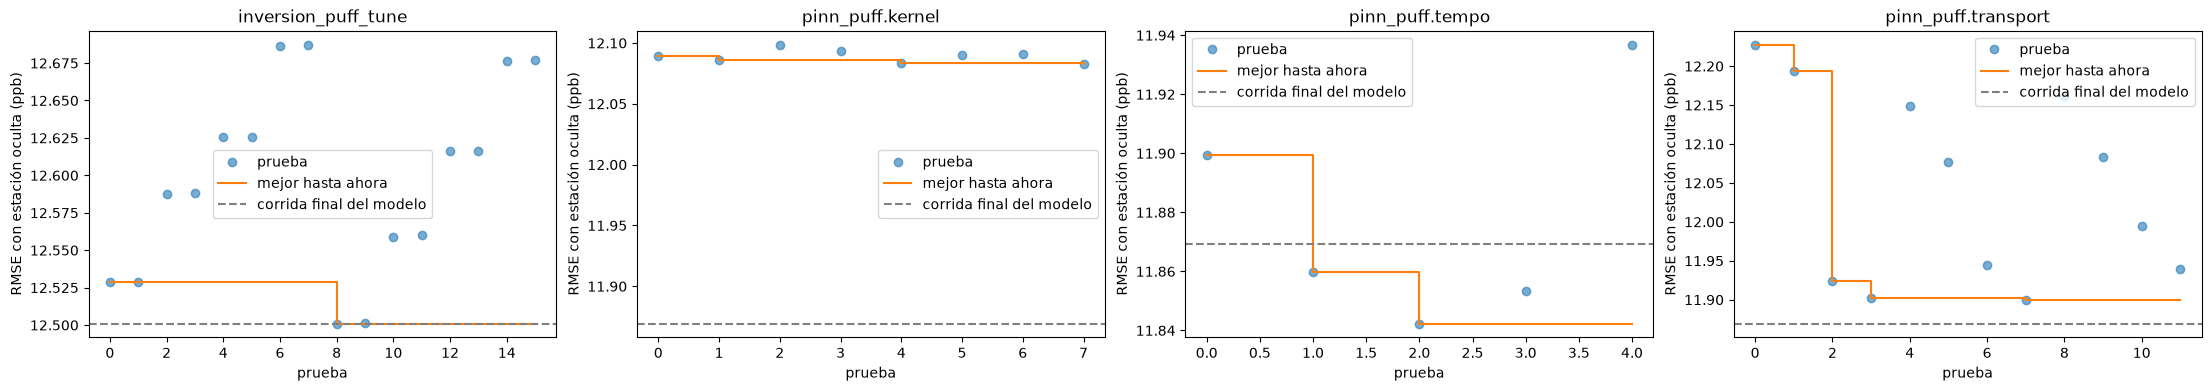

In [11]:
report.plot_trials(RUNS, ranked)

Qué se obtuvo del ajuste (ppb de `loo_rmse_ppb`).

- E5b: de 12.08 a 11.87 (−0.21 ppb, 1.7 %). La configuración de partida (`u_min` 1.0 m/s, sin vida por OH) daba 12.08 (prueba 5 de la búsqueda de transporte). `u_min` = 2.0 aporta −0.18 (11.90) y la vida química por OH, −0.03 (11.87). Todos los cambios caen dentro del ruido de ±0.5 ppb del experimento 4: el modelo es robusto a sus hiperparámetros. Las mejoras de `u_min` y de la red se leen como robustez, no como ganancias reales.
- La red no importa: las 8 pruebas quedan entre 12.083 y 12.099 ppb (0.016 de rango). El peso de TEMPO tampoco: de `tempo_sigma_mult` 1 a 10 el error se mueve entre 11.84 y 11.94; el mejor valor, 3, ahorra 0.06 ppb pero ensancha el placebo (±0.18 frente a ±0.12), por eso se conserva 1.
- `kappa` 3 000 sí es claramente peor (12.60 frente a 11.90 con el mismo ajuste sin OH, +0.7 ppb, mayor que el ruido); 500, 1 000 y 1 500 m quedan dentro de 0.1 ppb entre sí (sección de `kappa`).
- La vida química por OH estrecha el placebo de E5b de ±0.20 a ±0.12 (`pinn_puff.transport` frente a `pinn_puff`): es el beneficio real de esa decisión, más que el error.
- E2: 12.50, sin mejora sobre su configuración final. La rejilla de 16 pruebas va de 12.50 a 12.69 (0.19 de rango). La mejor (`max_age_h` 24, OH, `tempo_sigma_mult` 1, sin restricción de tráfico) es la que ya estaba en `inversion_puff.yaml`: la búsqueda confirma esa configuración. Por factor (promedio de las pruebas): la vida por OH baja 0.11 ppb frente a la vida fija (12.54 frente a 12.65), `max_age_h` 24 frente a 12 y `tempo_sigma_mult` 3 frente a 1 mueven 0.02 y 0.06, y la restricción de tráfico no cambia el error (12.598 con y sin ella). Su refit sigue elegible (placebo 0.97 ± 0.16).
- Curvas de prueba. Las búsquedas son rejillas o muestreos sin orden, así que no se «aplanan» como una búsqueda secuencial; lo que muestran es el rango: de E5b-transporte, todas las pruebas con `u_min` = 2.0 (11.90–11.99) quedan por debajo de todas las de `u_min` = 1.0 (12.08–12.23); de la red, una banda de 0.016 ppb; de E2, una banda de 0.19 ppb. La búsqueda fue suficiente para ver que no hay un óptimo agudo que encontrar.
- Sesgo del ajuste. Las cifras ajustadas son algo optimistas por usar validación no anidada; con ganancias dentro del ruido, el sesgo está acotado por el mismo ruido, y la evaluación sin sesgo es el avance 5 (feb–may 2024).

### Ajuste de `pinn_puff` (E5b)

El ajuste de `pinn_puff` se hizo en tres búsquedas separadas, porque sus hiperparámetros cuestan muy distinto:

| Búsqueda (`runs/`) | Qué mueve | Costo por prueba |
|---|---|---|
| `pinn_puff.transport` | `u_min`, `max_age_h` y `tau_h`: no reentrenan la red, solo cambian cómo se arman los puffs | Armar las matrices de transporte |
| `pinn_puff.kernel` | Los hiperparámetros de la red (capas, ancho, tasa de aprendizaje, peso de la física) | Entrenar una red nueva |
| `pinn_puff.tempo` | `tempo_sigma_mult`: cuánto se desconfía de TEMPO (1 a 10) | Armar las matrices (la misma caché) |

Las tablas siguientes salen de `trials.csv` de cada búsqueda (si todavía no existe, la celda lo dice). Para cada una: el espacio explorado, el efecto de cada parámetro (correlación de rangos con el error: cerca de 0, el parámetro no importó; negativa, más es mejor) y la mejor prueba.

In [12]:
for name in ("pinn_puff.transport", "pinn_puff.kernel", "pinn_puff.tempo"):
    frame = trials.get(name)
    if frame is None:
        print(f"== {name}: sin trials.csv (todavía no se corrió esta búsqueda) ==")
        continue
    rmse = frame["loo_rmse_ppb"]
    print(f"== {name}: {len(frame)} pruebas, RMSE entre {rmse.min():.2f} y {rmse.max():.2f} ppb ==")
    print(report.param_effects(frame).round(3).to_string(index=False))
    print("Mejor prueba:")
    print(report.best_trial(frame).to_string())

== pinn_puff.transport: 12 pruebas, RMSE entre 11.90 y 12.23 ppb ==
    param  rank_corr  best_by_value_spread_ppb  best_value
    tau_h      0.000                     0.040        12.0
    u_min     -0.869                     0.178         2.0
max_age_h     -0.290                     0.024        24.0
Mejor prueba:
trial            7.000000
tau_h           12.000000
u_min            2.000000
max_age_h       24.000000
loo_rmse_ppb    11.899453
== pinn_puff.kernel: 8 pruebas, RMSE entre 12.08 y 12.10 ppb ==
         param  rank_corr  best_by_value_spread_ppb  best_value
         width     -0.405                     0.011      96.000
        layers      0.436                     0.006       3.000
physics_weight      0.262                     0.016       1.419
 learning_rate      0.238                     0.016       0.001
Mejor prueba:
trial              7.000000
width             96.000000
layers             3.000000
physics_weight     1.418809
learning_rate      0.001132
loo_rmse_ppb  

Búsqueda del transporte (`pinn_puff.transport`).

- El mejor valor es `u_min` = 2.0 m/s: el error con estación oculta baja de 12.08 a 11.90 ppb (−0.18 ppb, ~1.5 %). Esa ganancia no es distinguible del ruido: el error con estación oculta cambia ~±0.5 ppb solo por la semilla y las estaciones usadas (experimento 4). Se lee como que el modelo es robusto a sus hiperparámetros, no como una mejora real.
- `max_age_h` = 24 queda ligeramente mejor que seguir a los puffs menos tiempo: la memoria larga ayuda un poco, pero poco.
- `tau_h` casi no importa para el error, pero no porque no pierda masa: la pérdida de masa con `tau_h` depende de la velocidad del viento (decae como `exp(−x / uτ)`; experimento 1: con 3 m/s y 12 h, a 45 km queda cerca del 68 %), y con los vientos débiles de estas tardes es mayor. Variar `tau_h` apenas mueve el error porque la química entra solo como una vida constante.

Búsqueda de la red (`pinn_puff.kernel`).

- Todas las pruebas quedan entre 12.08 y 12.10 ppb. Los hiperparámetros de la red no importan: redes distintas dan prácticamente la misma matriz fuente–receptor. Lo más probable es que la red ya resuelva la ecuación con suficiente exactitud (1.7–4.7 % frente a la solución exacta, medido en este repositorio; experimento 1) y que el error restante venga del transporte (un solo viento uniforme para todo el dominio) y no de la red.
- Conclusión práctica: no vale la pena gastar cómputo en entrenar redes más grandes, y tampoco en afinar `u_min` o `max_age_h` (dentro del ruido). Lo que sí cambia el transporte es la física (`kappa`, siguiente apartado) y el tipo de transporte (pluma o puffs, experimento 5).

Búsqueda del peso de TEMPO (`pinn_puff.tempo`).

- Cinco valores de `tempo_sigma_mult` (1, 2, 3, 5, 10) dan entre 11.84 y 11.94 ppb: 0.1 ppb de rango, dentro del ruido. El mejor es 3 (11.84), pero su placebo (1.02 ± 0.18) es más ancho que el de 1 (1.01 ± 0.12 en la corrida final), así que se conserva 1.
- La conclusión es la de las otras búsquedas: el modelo es robusto al peso de TEMPO; el satélite empuja el cociente del domingo hacia abajo en la inversión de pluma (ver diagnóstico del baseline) pero en este modelo apenas lo mueve (0.48 con peso 1 y 0.46 con peso 3).

La curva de pruebas y el resumen de las búsquedas aparecen también en las celdas generales de esta sección.

### La difusividad `kappa` de la PINN

`kappa` no es un hiperparámetro de la red sino un parámetro de la física. La ecuación usa una difusividad turbulenta proporcional al viento, K = kappa · |u|, así que `kappa` es una longitud de difusión en metros (la difusividad por unidad de velocidad del viento) y representa el serpenteo del viento: con el valor de la investigación, 1 500 m, la pluma tiene el ancho de una con 30° de dispersión del viento a unos 10 km.

Dos consecuencias:

- Cada valor de `kappa` es otra ecuación (entra como `eps = kappa / L`, el inverso de un número de Péclet, con L = 10 km) y el núcleo no se puede reescalar de forma exacta; por eso cada valor entrena y guarda su propia red (~3–18 min, una vez). Con el valor por defecto se usa la red incluida en el paquete.
- A diferencia de los hiperparámetros de la red, `kappa` sí cambia el transporte: una `kappa` grande ensancha y diluye la pluma; una pequeña la deja angosta y concentrada.

Rejilla `pinn_puff_k*`: una corrida de `pinn_puff` por valor de `kappa` (mismos datos, mismos puffs; solo cambia la ecuación). Estas corridas no entran en la tabla comparativa de la sección 3, porque son variantes de un mismo modelo y no competidores; la fila `pinn_puff` de abajo es el valor por defecto.

In [13]:
grid = report.kappa_grid(RUNS)
if grid.empty:
    print("Sin corridas pinn_puff_k* todavía (nox-ml run con kappa en la configuración de pinn_puff).")
grid.round(2)

,kappa_m,run,loo_rmse_ppb,loo_bias_ppb,sunday_ratio,eligible,fit_seconds
0,500.0,pinn_puff_k500,11.86,5.17,0.49,True,679.81
1,1000.0,pinn_puff_k1000,11.80,4.96,0.47,True,721.42
2,1500.0,pinn_puff,11.87,5.22,0.48,True,528.94
3,1500.0,pinn_puff_k1500,11.90,4.98,0.47,True,526.52
4,3000.0,pinn_puff_k3000,12.60,5.73,0.47,True,685.47


Resultados de la rejilla de `kappa` (la fila `pinn_puff_k1500` es el ajuste de transporte sin vida por OH, comparable con las otras tres; la fila `pinn_puff` es la corrida final con OH, también con `kappa` 1 500):

| `kappa` (m) | `loo_rmse_ppb` | Domingo/hábil | Placebo | `fit_seconds` |
|---|---|---|---|---|
| 500 | 11.86 | 0.49 | 1.05 ± 0.19 | 680 |
| 1 000 | **11.80** | 0.47 | 1.04 ± 0.19 | 721 |
| 1 500 | 11.90 | 0.47 | 1.02 ± 0.20 | 527 |
| 3 000 | 12.60 | 0.47 | 0.99 ± 0.21 | 685 |

- El mínimo es plano entre 500 y 1 500 m: 11.80–11.90, un rango de 0.1 ppb, dentro del ruido y menor que el efecto de `u_min` (0.18). El valor de 1 000 m no es distinguible de 1 500 m; es compatible con el 1 500 m de la investigación.
- 3 000 m es claramente peor (+0.7 ppb sobre 1 500 m, más que el ruido de ±0.5): una pluma demasiado ancha diluye la señal. Es el único cambio de `kappa` que sí importa.
- El domingo/hábil casi no se mueve con `kappa` (0.47–0.49) y todas las `kappa` pasan el placebo (centro entre 0.99 y 1.05).
- Cada valor cuesta lo mismo (527–721 s, incluye entrenar su red), así que no hay razón de costo para preferir uno. Se conserva 1 500 m: es el valor de la red incluida en el paquete (sin reentrenar), su placebo con OH es el más estrecho (±0.12) y la rejilla no justifica el cambio. La rejilla es pequeña (4 valores, una sola semilla): descarta 3 000 m, no ordena los demás.

## 6. Modelo final

La métrica principal no basta para elegir. Los argumentos que cuentan:

- error con estación oculta (`loo_rmse_ppb`);
- exactitud del cambio de emisión: cociente domingo/hábil frente al rango del tráfico contado, con su intervalo;
- placebos: centro cerca de 1 y semiancho (el cambio mínimo que el modelo podría detectar);
- interpretabilidad (factores por zona);
- incertidumbre de la emisión estimada;
- emisión absoluta o solo relativa;
- costo de ajuste y de predicción.

In [14]:
final = report.models(ranked, ["pinn_puff", "inversion_puff"])
final[
    [
        "id",
        "model",
        "loo_rmse_ppb",
        "loo_bias_ppb",
        "loo_hourly_rmse_ppb",
        "r_tempo",
        "sunday_ratio",
        "sunday_ratio_lo",
        "sunday_ratio_hi",
        "sunday_ratio_gap",
        "placebo_center",
        "placebo_halfwidth",
        "fit_seconds",
        "predict_seconds",
        "n_params",
    ]
].round(2)

,id,model,loo_rmse_ppb,loo_bias_ppb,loo_hourly_rmse_ppb,r_tempo,sunday_ratio,sunday_ratio_lo,sunday_ratio_hi,sunday_ratio_gap,placebo_center,placebo_halfwidth,fit_seconds,predict_seconds,n_params
0,E5b,pinn_puff,11.87,5.22,10.66,0.85,0.48,0.36,0.62,0.17,1.01,0.12,528.94,0.09,12832
1,E2,inversion_puff,12.50,5.61,11.17,0.84,0.52,0.44,0.59,0.13,0.97,0.16,322.57,0.10,31


### Modelo final: E5b `pinn_puff`

Decisión: el modelo final es E5b `pinn_puff` (configuración de `configs/experiments/pinn_puff.yaml`: `u_min` 2.0, `lifetime: oh`, `kappa` 1 500 m, `tau_h` 12, `max_age_h` 24). Los argumentos, un criterio por viñeta frente a E2, su rival más cercano:

- Error con estación oculta. Mejor de la tabla: 11.87 frente a 12.50 ppb de E2 (−0.63 ppb, 5 %). La ventaja es modesta pero consistente: está apenas por encima del ruido de ±0.5 ppb y aparece también en el error horario (10.66 frente a 11.17), el sesgo (5.22 frente a 5.61) y la correlación con TEMPO (0.85, la más alta, frente a 0.84). Como modelo híbrido (el modelo más IDW de los residuos de las otras estaciones) llega a 10.4 ppb y le gana a IDW en 17–19 de las 24 estaciones: la física de E5b aporta información que IDW no tiene.
- Exactitud del cambio de emisión. Aquí E2 es ligeramente mejor: domingo/hábil 0.52 (0.44–0.59) frente a 0.48 (0.36–0.62), brecha 0.13 frente a 0.17. Los intervalos se traslapan casi por completo y ambos quedan por debajo de 0.65–0.73; se acepta la diferencia porque no es significativa y porque ningún modelo de la tabla resuelve el defecto (ver limitaciones).
- Placebo. Ambos pasan (E5b 1.01 ± 0.12, E2 0.97 ± 0.16). E5b tiene el semiancho más estrecho de los modelos con emisión absoluta: detecta cambios de ~12 % frente a ~16 % de E2 y a ~33 % de los modelos de pluma.
- Interpretabilidad e incertidumbre. Igual que E2: factores por zona y tipo de día con intervalos por bootstrap. La capa de emisiones es la misma inversión bayesiana; la red solo aporta el transporte, se entrena sin ver datos (no puede filtrar información de la estación oculta) y reproduce la solución exacta con 1.7–4.7 % de error.
- Emisión absoluta o relativa. Absoluta, pero su nivel depende del transporte (sección 3: 30 kt/año de emisión vial hábil frente a 60 de E2); lo robusto son los cocientes. E6 y E7 solo dan emisión relativa.
- Costo. Se ajusta en ~9 min (529 s) frente a ~5 min (323 s) de E2; predecir cuesta ~0.1 s en los dos. Es un costo asumible; E5a (16 s, 12.49) queda como alternativa barata.
- Extensibilidad (ventaja futura, no medida aquí). La PINN abre estimar parámetros físicos (`kappa`, vida química, capa límite) o química no lineal, que un núcleo analítico no permite. No se midió en este avance; no sustenta la elección.

Limitaciones.

- Todos los modelos subestiman el domingo/hábil (0.42–0.56 frente a 0.65–0.73 del tráfico contado). La restricción de tráfico solo lo corrige imponiéndolo, y rompe el placebo (revisión de la restricción con datos reales): no se usa. Sin ella no hay un defecto que el ajuste fino pueda arreglar (E2: la restricción no cambia el error). Para ponerlo en contexto, Fioletov et al. (2025) reportan bajas de NO₂ de 30–60 % en domingo en columnas de TEMPO (0.40–0.70 como cociente), un rango que incluye lo que estiman los modelos, pero ese estudio mide columnas y no emisiones.
- Kriging gana a todos los modelos en concentración (10.33 frente a 11.87) y IDW también (11.57); no estiman emisión, que es el objetivo del proyecto. La física no gana en concentración sola.
- Intervalos: el de E4 es demasiado estrecho (0.44–0.46, aproximación de Laplace); el centro del placebo de E7 (0.88) queda cerca del borde de 1 ± 0.15.
- Ajuste no anidado (optimista, justificado por costo) y sin periodo de prueba hasta el avance 5 (feb–may 2024): el error de 11.87 ppb es el de nov–dic 2023.
- Todas las ganancias del ajuste están dentro del ruido de ±0.5 ppb; la elección entre E5b y E2 se apoya en una diferencia modesta, y el avance 5 la pondrá a prueba.
- E5c `pinn_joint` quedó fuera con la evidencia de la investigación (sección 2.3: peor error, 12.9 frente a 11.6 ppb, y 12–17 veces más tiempo).
- `kappa` se probó en una rejilla pequeña (sección 5) y la red se entrenó con una sola semilla.

## 7. Declaración del uso de herramientas de IA

### 1. Uso de inteligencia artificial

- Herramientas:
  - Claude Code (Anthropic), modelos Claude Opus 5.5 y Claude Sonnet 5.5.
  - ChatGPT (OpenAI), modelo GPT-6.

- Finalidad: apoyo, no autoría. Se usaron para:
  - explicar conceptos y algoritmos (inversión bayesiana lineal, puffs, normalización meteorológica) y métricas de evaluación;
  - consultar sintaxis de Python, pandas, NumPy y pytest, resolver dudas de programación y depurar errores puntuales;
  - generar código de utilidades, que nos permite experimentar y enfocarnos en el código de los modelos y revisar código de los modelos
  - refactorización de parte del código de notebooks de investigación a módulos
  - generar pruebas de los modelos una vez que un humano decidió qué aspectos importa probar;
  - revisar los pull requests
  - mejorar la claridad y organización de la documentación técnica;

  Cada fragmento de código fue revisado, adaptado y probado por el equipo.

- Lo que no se delegó:
  - La selección de métodos, las decisiones técnicas, la interpretación de resultados y las conclusiones son del equipo.
  - Las sugerencias de código se contrastaron con pruebas automatizadas (pruebas de contrato, de física y de reproducción de la investigación), con la revisión de cada pull request y con corridas con datos reales. La interpretación de resultados corresponde al equipo.

- Referencias:
  - Anthropic. (2026, 16 de octubre). Exploración de proyectos prácticos usando PINNs [Chat de IA generativa]. Claude Haiku 5.5. https://claude.ai/chat/208deba4-35ed-452e-a7ae-97a18dea8932

### 2. Contribución de los integrantes

- Isabella Arango Restrepo: Implementó el modelo `inversion_puff` (E2), con su transporte de puffs sobre `jacobian_hour_puff`, sus pruebas y su configuración de experimento. Corrió E2 con datos de nov–dic 2023 y comparó sus métricas con E1 (baseline). Diseñó la grilla de ajuste de 16 combinaciones y corrió `nox-ml tune`; la mejor combinación fue la configuración por defecto (12.50 ppb en estación oculta). Además implementó el peso de TEMPO (`tempo_sigma_mult`) y la restricción opcional del cociente domingo/hábil con el tráfico, heredados por los modelos de inversión. 
- Isaí Ambrocio: revisó y validó el estimador normalizado (E7, `normalized_ratio`) con datos de nov–dic 2023, comparándolo con el baseline. En la corrida oficial, E7 obtuvo un error en estación oculta (LOO RMSE) de 16.75 ppb frente a 13.59 del baseline, un cociente domingo/hábil de 0.56 (0.46–0.71) y un placebo de 0.88 ± 0.22. El cociente puede estar sesgado hacia 1 por el fondo de las observaciones.
- Manuel Alejandro Vázquez Meza: coordinación técnica del avance 4. Diseñó la estructura del repositorio (workspace con uv, DVC en DagsHub, pre-commit, integración continua) y el contrato de modelos, y migró la fase de investigación al repositorio. Implementó y evaluó los modelos con PINN (`pinn_plume`, E5a, y `pinn_puff`, E5b) y la normalización meteorológica (`rf_deweather`, E6). Hizo el ajuste fino de E5b (transporte, red, difusión κ, peso de TEMPO y vida química por OH) y compiló las corridas finales de todos los modelos con datos de nov–dic 2023.

### 3. Decisiones técnicas

Las tres decisiones del avance 4 que más condicionaron sus resultados.

#### 3.1 Ajuste fino: qué ajustar, cómo repartir el cómputo y cómo leer el resultado

Problema. El avance pedía ajustar los dos mejores modelos. E5b era claramente el primero (11.87 ppb), pero E5a (12.49) y E2 (12.50) empataban en error, con una diferencia 50 veces menor que el ruido de ±0.5 ppb que tiene el error con estación oculta entre corridas equivalentes. Además, los hiperparámetros de E5b cuestan muy distinto: cambiar la red obliga a entrenarla de nuevo, cambiar el transporte obliga a rearmar las matrices y cambiar el peso de TEMPO solo reusa la caché. Cada prueba de E5b tarda de 8 a 12 minutos.

Decisión. Se eligió E2 como segundo modelo y no E5a, aunque empataban. E2 tiene exactamente la misma física que E5b (puffs de hasta 24 horas y química por OH) y solo cambia el núcleo de transporte, analítico en E2 y aprendido en E5b; ajustar los dos responde la pregunta científica del avance, si el núcleo aprendido aporta algo. Además, E2 es mejor que E5a en lo que importa para la emisión: brecha del domingo 0.13 frente a 0.23, placebo ±0.16 frente a ±0.33 y correlación con TEMPO 0.84 frente a 0.78. Para E5b, el ajuste se separó en búsquedas según su costo: transporte (rejilla de 12 pruebas), red (8 pruebas aleatorias), peso de TEMPO (5 valores) y difusividad `kappa` (4 valores); para E2, una rejilla de 16 pruebas. Los resultados se leyeron contra el ruido: una diferencia menor a ±0.5 ppb no se tomó como mejora.

Alternativas descartadas. Elegir el segundo modelo solo por el error, que en un empate equivale a elegir al azar. Una sola búsqueda aleatoria conjunta sobre todos los hiperparámetros de E5b, que habría gastado la mayor parte del cómputo en reentrenar redes. Una validación anidada, con una búsqueda completa por cada estación oculta: es lo correcto para no sesgar el error, pero cuesta unas 24 veces más, más de 4 días de CPU para E5b, y no cambiaría qué modelos pasan.

Consecuencias. Las búsquedas mostraron que E5b es robusto: las 8 redes quedan en una banda de 0.016 ppb, el peso de TEMPO mueve el error solo 0.1 ppb y el viento mínimo de 2 m/s baja de 12.08 a 11.90, también dentro del ruido. El único cambio que sí importa es `kappa` = 3 000 m, claramente peor (+0.7 ppb). La mejora real del ajuste no fue de error sino de placebo: la vida química por OH lo estrecha de ±0.20 a ±0.12, es decir, el modelo detecta cambios de emisión más pequeños. Se conservaron los valores por defecto donde una alternativa ganaba por menos que el ruido y empeoraba el placebo (el peso de TEMPO 3 ahorra 0.06 ppb pero ensancha el placebo a ±0.18). En E2 la rejilla confirmó la configuración que ya tenía. El error ajustado es algo optimista por no ser anidado; la medición sin sesgo es el avance 5, sobre febrero a mayo de 2024, un periodo que no se usó para ajustar ni elegir.

#### 3.2 Una sola inversión con transporte intercambiable, y una PINN que solo aprende física

Problema. Los modelos E1, E2, E5a y E5b responden la misma pregunta con la misma inversión bayesiana (zonas, supuesto inicial, fondo horario, TEMPO, intervalos por bootstrap), y difieren en cómo se calcula el transporte de la fuente al receptor: pluma gaussiana estacionaria, puffs con memoria de 24 horas, o un núcleo aprendido por una red neuronal informada por la física (PINN). Si cada uno se implementara por separado, una diferencia en la tabla podría venir de un detalle de implementación y no del transporte.

Decisión. Los cuatro heredan la misma clase de inversión y solo sustituyen la matriz de transporte. Así, E5a frente a E1 mide lo que aporta el núcleo aprendido con el mismo tipo de transporte, y E5b frente a E5a mide lo que aporta la memoria de los puffs. Las matrices se guardan en una caché con una clave propia de cada transporte, de modo que los 24 reajustes de la validación y los del placebo tardan minutos en lugar de horas. La PINN se entrena solo con la ecuación de advección–difusión, sin ver datos de estaciones, y una sola vez para todo el ejercicio.

Alternativas descartadas. La alternativa principal era E5c, una PINN entrenada con la física y las estaciones a la vez. Tiene dos problemas: al ver las estaciones, habría que reentrenarla en cada pliegue de la validación para que no filtre la estación oculta, y en la investigación dio peor error (12.9 frente a 11.6 ppb) y tardó de 12 a 17 veces más. También se descartó escribir cada modelo como un script independiente, porque la comparación dejaría de ser controlada.

Consecuencias. La comparación aisló el factor que más importa: el salto grande viene de los puffs (E5a a E5b: −0.62 ppb, placebo de ±0.33 a ±0.12), no del núcleo aprendido. También mostró una limitación: con las mismas observaciones, el nivel absoluto de emisión cambia por un factor de hasta 2 según el transporte (por ejemplo, 30 frente a 60 kt/año de emisión vial en día hábil entre E5b y E2). Por eso el proyecto reporta sobre todo cocientes, como domingo/hábil, que son robustos al transporte, y no toneladas absolutas.

#### 3.3 No imponer la restricción de tráfico, y excluirla del placebo

Problema. Todos los modelos subestiman el domingo/hábil: estiman 0.42 a 0.56 cuando el tráfico contado por Infovial indica 0.65 a 0.73. El diagnóstico del baseline mostró que el satélite empuja ese cociente hacia abajo. Una forma directa de corregirlo es agregar el cociente del tráfico como una observación más de la inversión, con su incertidumbre (`traffic_sd`).

Decisión. La restricción quedó implementada como parámetro opcional de los modelos de inversión, pero no se usa en el modelo final. Además, cuando está activa, nunca se aplica en los reajustes del placebo: el código la omite cuando los tipos de día son los reetiquetados (`InversionPlume.constraints`).

Alternativas descartadas. Con datos reales, una restricción débil (`traffic_sd` 0.04) casi no mueve el domingo (0.42 a 0.43). Una fuerte (0.01 a 0.002) lo sube a 0.54–0.68, pero solo porque lo impone: comparar después el domingo estimado con el tráfico sería circular, porque se le dio la respuesta. Y si la restricción se aplicara también a los domingos falsos del placebo, el centro bajaría a 0.70: el modelo vería una baja dominical donde no existe y dejaría de ser elegible. En el ajuste de E2, la restricción no mejoró el error con estación oculta.

Consecuencias. El modelo final se reporta con su subestimación del domingo a la vista, como limitación conocida, en lugar de corregirla de forma cosmética. La restricción sigue disponible para estudiar en el avance 5 (por ejemplo, por región, como en la investigación), siempre con el placebo sin restricción y sin usar el domingo como validación cuando se haya impuesto.